# Notebook 4 : apprentissage semi-supervisé

Dans la base `welddb`, beaucoup de lignes n'ont pas de valeur pour une propriété mécanique donnée (par exemple 872 lignes sur 1652 n'ont pas de Yield_strength). Ces lignes ont pourtant leurs variables d'entrée (composition, procédé, traitement). L'apprentissage semi-supervisé cherche à utiliser ces lignes **non labellisées** en plus des lignes labellisées pour mieux apprendre.

Question posée : **est-ce que les lignes non labellisées améliorent la prédiction de soudures issues d'études jamais vues** (même protocole de validation par groupe que dans le notebook 3) ?

## 1. Etat de l'art et choix de la méthode

Principales familles de méthodes semi-supervisées (van Engelen & Hoos, 2020 ; Chapelle et al., 2006) :
- **Auto-apprentissage (self-training / pseudo-labelling)** : on entraîne un modèle sur les données labellisées, on prédit les lignes non labellisées, on ajoute les prédictions les plus sûres comme « pseudo-labels », puis on ré-entraîne (Yarowsky, 1995 ; Lee, 2013).
- **Co-apprentissage (co-training)** : deux modèles s'échangent leurs prédictions les plus sûres. Pour la régression, la méthode de référence est COREG (Zhou & Li, 2005), qui utilise deux régresseurs kNN.
- **Méthodes à base de graphe** (propagation de labels) : surtout développées pour la classification.
- **Réseaux de neurones semi-supervisés** (mean teacher, etc.) : demandent beaucoup de données.

**Choix : auto-apprentissage avec une Random Forest.**
- Notre problème est une **régression** : les méthodes de propagation de labels de scikit-learn ne s'y appliquent pas.
- Avec 500 à 600 lignes labellisées, un réseau profond n'est pas adapté.
- La Random Forest est un de nos deux meilleurs modèles (notebook 3). Elle donne aussi une mesure naturelle de **confiance** : la dispersion des prédictions des arbres. Une ligne dont tous les arbres s'accordent est plus fiable qu'une ligne où ils divergent.
- La méthode est simple, ce qui permet de la valider proprement. COREG repose sur kNN, qui est le plus mauvais modèle de notre étude.

**Hypothèse sous-jacente** : les lignes proches dans l'espace des variables ont des propriétés proches (hypothèse de regroupement / cluster). C'est plausible ici car les soudures forment des séries de compositions voisines (voir l'ACP du notebook 2).

**Risque principal** : le *biais de confirmation*. Si une prédiction est fausse mais jugée sûre, elle est ajoutée comme vérité puis renforcée. On limite ce risque avec un poids réduit pour les pseudo-labels et en n'ajoutant que les prédictions les plus sûres.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

PROCESSED_DIR = os.path.join("..", "data", "processed")
TARGETS_SSL = ["Yield_strength", "UTS", "Elongation", "Reduction_area"]   # Charpy_energy : voir plus bas
CAT_COLS = ["AC_DC", "Polarity", "Weld_type"]
ALLOY_COLS = ["Cu_wt", "Mo_wt", "Ni_wt", "Cr_wt", "V_wt"]
DROP_COLS = ["W_wt", "Co_wt"]
ALLOY_INDICATOR = True
FLAG_COLS = ["O_ppm", "N_ppm", "Current_A", "Voltage_V"]
RANDOM_STATE = 42

## 2. Chargement

On recharge les données labellisées (mêmes fichiers que le notebook 3) et les lignes non labellisées exportées par le notebook 1.

In [2]:
def add_features(X):
    """Deterministic feature engineering (no statistic learned from the data)."""
    X = X.copy()
    X["PWHT_done"] = (X["PWHT_temp"] > 0).astype(float)
    return X


def load_target(target):
    """Labelled rows: raw train / test split of one target (exported by notebook 1)."""
    path = os.path.join(PROCESSED_DIR, f"welddb_split_{target.lower()}.csv")
    data = pd.read_csv(path)
    out = {}
    for split in ["train", "test"]:
        part = data[data["split"] == split].drop(columns="split").reset_index(drop=True)
        X = add_features(part.drop(columns=[target, "group"] + DROP_COLS, errors="ignore"))
        out[split] = (X, part[target])
        out[f"groups_{split}"] = part["group"]
    return out


def load_unlabeled(target):
    """Unlabelled rows: same features, no value for the target."""
    path = os.path.join(PROCESSED_DIR, f"welddb_unlabeled_{target.lower()}.csv")
    data = pd.read_csv(path)
    X = add_features(data.drop(columns=["group"] + DROP_COLS, errors="ignore"))
    return X, data["group"]


datasets = {t: load_target(t) for t in TARGETS_SSL}
unlabeled = {t: load_unlabeled(t) for t in TARGETS_SSL}
for t in TARGETS_SSL:
    assert list(datasets[t]["train"][0].columns) == list(unlabeled[t][0].columns)
    print(f"{t:>15}: {len(datasets[t]['train'][0])} lignes labellisées (train) | {len(unlabeled[t][0])} lignes non labellisées")

 Yield_strength: 590 lignes labellisées (train) | 872 lignes non labellisées
            UTS: 545 lignes labellisées (train) | 914 lignes non labellisées
     Elongation: 473 lignes labellisées (train) | 952 lignes non labellisées
 Reduction_area: 552 lignes labellisées (train) | 947 lignes non labellisées


### Pourquoi pas Charpy_energy ?

Pour Charpy_energy, les lignes non labellisées n'ont pas non plus de `Charpy_temp` (la température de l'essai), qui est notre variable la plus importante pour cette cible. Sans elle, une ligne ne peut pas être utilisée. Vérification :

In [3]:
X_unl_charpy = pd.read_csv(os.path.join(PROCESSED_DIR, "welddb_unlabeled_charpy_energy.csv"))
print(f"Lignes non labellisées pour Charpy_energy : {len(X_unl_charpy)}")
print(f"dont Charpy_temp manquante : {X_unl_charpy['Charpy_temp'].isna().sum()}")

Lignes non labellisées pour Charpy_energy : 773
dont Charpy_temp manquante : 773


### Que contient vraiment la partie non labellisée ?

Une même soudure apparaît souvent sur plusieurs lignes (avec des essais différents), donc beaucoup de lignes non labellisées sont des **doublons exacts** (mêmes variables d'entrée) d'une autre ligne, ou d'une ligne déjà labellisée. Elles n'apportent aucune information nouvelle. On compte ce qui reste de vraiment nouveau.

In [4]:
def row_key(X):
    """One string per row, to detect identical rows."""
    return X.fillna(-1).astype(str).agg("|".join, axis=1)


rows = []
for t in TARGETS_SSL:
    X_lab, _ = datasets[t]["train"]
    X_unl, g_unl = unlabeled[t]
    keys_unl = row_key(X_unl)
    keys_lab = set(row_key(X_lab))
    new_rows = X_unl[~keys_unl.isin(keys_lab)]
    new_rows = new_rows[~row_key(new_rows).duplicated()]
    rows.append({
        "target": t,
        "labellisées (train)": len(X_lab),
        "non labellisées": len(X_unl),
        "sans doublon": int((~keys_unl.duplicated()).sum()),
        "vraiment nouvelles": len(new_rows),
        "groupes concernés": g_unl.loc[new_rows.index].nunique(),
    })
pd.DataFrame(rows).set_index("target")

,labellisées (train),non labellisées,sans doublon,vraiment nouvelles,groupes concernés
target,,,,,
Yield_strength,590,872,397,295,40
UTS,545,914,413,300,41
Elongation,473,952,454,400,50
Reduction_area,552,947,446,371,66


Sur les 872 à 952 lignes non labellisées, il reste environ 300 à 400 lignes **vraiment nouvelles** selon la cible, soit de 50 % à 85 % du nombre de lignes labellisées : l'enjeu est réel.

## 3. Prétraitement (identique au notebook 3)

In [5]:
def make_preprocessor(columns):
    """Unfitted preprocessing: everything is learned on the training data only."""
    flag_cols = [c for c in FLAG_COLS if c in columns]
    ppm_cols = [c for c in columns if c.endswith("_ppm") and c not in flag_cols]
    alloy_cols = [c for c in ALLOY_COLS if c in columns]
    cat_cols = [c for c in CAT_COLS if c in columns]
    other_cols = [c for c in columns if c not in ppm_cols + flag_cols + alloy_cols + cat_cols]

    ppm_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value=0.0, keep_empty_features=True)),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    flag_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    alloy_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value=0.0, add_indicator=ALLOY_INDICATOR, keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    other_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    cat_pipe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    return ColumnTransformer([
        ("ppm", ppm_pipe, ppm_cols),
        ("flag", flag_pipe, flag_cols),
        ("alloy", alloy_pipe, alloy_cols),
        ("other", other_pipe, other_cols),
        ("cat", cat_pipe, cat_cols),
    ])


def make_pipeline(model, columns):
    return Pipeline([("prep", make_preprocessor(columns)), ("model", clone(model))])


RF = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)

## 4. Auto-apprentissage avec Random Forest

Algorithme :
1. Entraîner la Random Forest sur les lignes labellisées.
2. Prédire les lignes non labellisées restantes. Pour chacune, la **confiance** est la dispersion (écart-type) des prédictions des 300 arbres : plus elle est faible, plus la prédiction est sûre.
3. Garder la fraction `frac` des lignes les plus sûres, leur donner comme label la prédiction moyenne, et les ajouter à l'entraînement avec un poids réduit (`weight`).
4. Répéter `n_iter` fois, puis entraîner le modèle final.

Réglages choisis : `n_iter = 3`, `frac = 0.3` (environ 66 % de la partie non labellisée est utilisée au bout de 3 tours), `weight = 0.5` (un pseudo-label compte deux fois moins qu'un vrai label). La sensibilité à `frac` est testée plus bas.

In [6]:
def self_training(model, columns, X_lab, y_lab, pool, n_iter=3, frac=0.3, weight=0.5):
    """Pseudo-labelling with a Random Forest: the predictions on which the trees agree most are added to the training set."""
    X_cur = X_lab.reset_index(drop=True)
    y_cur = y_lab.reset_index(drop=True)
    w_cur = np.ones(len(X_cur))
    pool = pool.reset_index(drop=True)

    for _ in range(n_iter):
        if len(pool) == 0:
            break
        pipe = make_pipeline(model, columns).fit(X_cur, y_cur, model__sample_weight=w_cur)

        # prediction of every tree on the pool: mean = pseudo-label, std = uncertainty
        Z = pipe.named_steps["prep"].transform(pool)
        all_trees = np.array([tree.predict(Z) for tree in pipe.named_steps["model"].estimators_])
        pred, spread = all_trees.mean(axis=0), all_trees.std(axis=0)

        n_add = max(1, int(frac * len(pool)))
        best = np.argsort(spread)[:n_add]                      # the most certain rows

        X_cur = pd.concat([X_cur, pool.iloc[best]], ignore_index=True)
        y_cur = pd.concat([y_cur, pd.Series(pred[best])], ignore_index=True)
        w_cur = np.concatenate([w_cur, np.full(n_add, weight)])
        pool = pool.drop(pool.index[best]).reset_index(drop=True)

    final = make_pipeline(model, columns).fit(X_cur, y_cur, model__sample_weight=w_cur)
    return final, len(X_cur) - len(X_lab)

## 5. Protocole de validation

On reprend le protocole du notebook 3 : **validation croisée par groupe** (5 folds, un groupe d'étude n'est jamais coupé), répétée avec 3 tirages différents pour réduire le bruit. Dans chaque fold on compare, avec exactement les mêmes lignes de validation :
- la Random Forest **supervisée** (lignes labellisées seulement) ;
- la Random Forest **auto-apprise** (mêmes lignes labellisées + pseudo-labels).

Précautions pour ne pas tricher, car les lignes non labellisées peuvent venir de la même étude que les lignes de validation :
- on **exclut** de la partie non labellisée les groupes de validation **et** les groupes du jeu de test final ;
- on exclut les lignes identiques à une ligne labellisée du train (aucune information nouvelle) et les doublons.

In [7]:
def prepare_pool(X_unl, g_unl, X_lab, groups_excluded):
    """Unlabelled rows that can be used: not in an excluded group, not identical to a labelled row, no duplicate."""
    keep = ~g_unl.isin(groups_excluded)
    keep = keep & ~row_key(X_unl).isin(set(row_key(X_lab)))
    pool = X_unl[keep]
    pool = pool[~row_key(pool).duplicated()]
    return pool.reset_index(drop=True)


def scores(y_true, y_pred):
    return {"r2": r2_score(y_true, y_pred),
            "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
            "mae": mean_absolute_error(y_true, y_pred)}

In [8]:
SEEDS = [0, 1, 2]
rows = []
for target in TARGETS_SSL:
    X_tr, y_tr = datasets[target]["train"]
    g_tr = datasets[target]["groups_train"]
    X_unl, g_unl = unlabeled[target]
    test_groups = set(datasets[target]["groups_test"])
    cols = list(X_tr.columns)

    for seed in SEEDS:
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (i_a, i_b) in enumerate(cv.split(X_tr, y_tr, g_tr)):
            X_a, y_a = X_tr.iloc[i_a], y_tr.iloc[i_a]
            X_b, y_b = X_tr.iloc[i_b], y_tr.iloc[i_b]
            pool = prepare_pool(X_unl, g_unl, X_a, set(g_tr.iloc[i_b]) | test_groups)

            sup = make_pipeline(RF, cols).fit(X_a, y_a)
            semi, n_used = self_training(RF, cols, X_a, y_a, pool)
            s_sup, s_semi = scores(y_b, sup.predict(X_b)), scores(y_b, semi.predict(X_b))

            rows.append({"target": target, "seed": seed, "fold": fold, "n_pool": len(pool), "n_pseudo": n_used,
                         "r2_sup": s_sup["r2"], "r2_semi": s_semi["r2"],
                         "rmse_sup": s_sup["rmse"], "rmse_semi": s_semi["rmse"]})
    print(f"{target}: done")

cv_ssl = pd.DataFrame(rows)

Yield_strength: done
UTS: done
Elongation: done
Reduction_area: done


In [9]:
cv_ssl["diff_r2"] = cv_ssl["r2_semi"] - cv_ssl["r2_sup"]
cv_ssl["diff_rmse"] = cv_ssl["rmse_semi"] - cv_ssl["rmse_sup"]

summary = cv_ssl.groupby("target").agg(
    r2_sup=("r2_sup", "mean"), r2_semi=("r2_semi", "mean"), diff_r2=("diff_r2", "mean"),
    rmse_sup=("rmse_sup", "mean"), rmse_semi=("rmse_semi", "mean"),
    folds_better=("diff_r2", lambda d: int((d > 0).sum())),
    n_folds=("diff_r2", "size"), pseudo_labels=("n_pseudo", "mean"),
).loc[TARGETS_SSL]
summary.round(3)

,r2_sup,r2_semi,diff_r2,rmse_sup,rmse_semi,folds_better,n_folds,pseudo_labels
target,,,,,,,,
Yield_strength,0.419,0.417,-0.002,64.588,64.778,6,15,136.533
UTS,0.477,0.463,-0.014,61.226,62.122,4,15,139.533
Elongation,0.304,0.304,0.000,3.605,3.593,7,15,178.200
Reduction_area,0.409,0.414,0.005,5.914,5.924,10,15,194.867


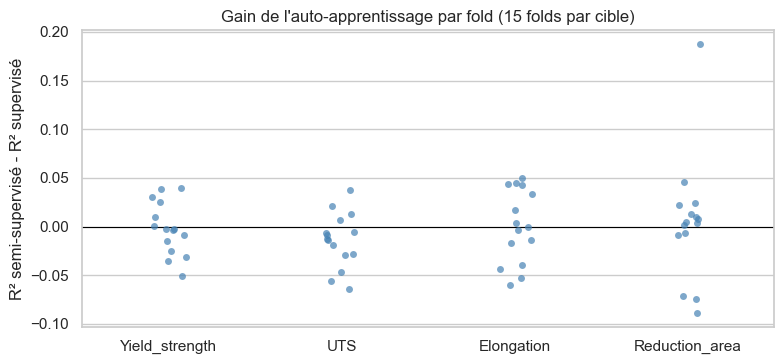

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.stripplot(data=cv_ssl, x="target", y="diff_r2", order=TARGETS_SSL, ax=ax, color="steelblue", alpha=0.7)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("")
ax.set_ylabel("R² semi-supervisé - R² supervisé")
ax.set_title("Gain de l'auto-apprentissage par fold (15 folds par cible)")
plt.tight_layout()
plt.show()

**Résultat : l'auto-apprentissage n'améliore pas la prédiction de soudures d'études jamais vues.**
- La différence moyenne de R² est comprise entre -0.014 et +0.005 selon la cible, avec seulement 4 à 10 folds améliorés sur 15 (la moitié ou moins pour 3 cibles sur 4). Ce n'est pas distinguable de zéro : l'écart-type du R² d'un fold à l'autre est de l'ordre de 0.2 (notebook 3).
- Les RMSE vont dans le même sens (pas de gain net).
- Environ 140 à 195 pseudo-labels sont ajoutés par fold, soit environ 30 à 45 % de lignes d'entraînement en plus.

## 6. Évaluation sur le jeu de test

On entraîne sur tout le train (labellisé), avec la partie non labellisée disponible (hors groupes du test), puis on évalue sur le jeu de test, qui n'a servi à rien jusqu'ici.

In [11]:
test_rows = []
for target in TARGETS_SSL:
    X_tr, y_tr = datasets[target]["train"]
    X_te, y_te = datasets[target]["test"]
    X_unl, g_unl = unlabeled[target]
    cols = list(X_tr.columns)

    pool = prepare_pool(X_unl, g_unl, X_tr, set(datasets[target]["groups_test"]))
    sup = make_pipeline(RF, cols).fit(X_tr, y_tr)
    semi, n_used = self_training(RF, cols, X_tr, y_tr, pool)
    s_sup, s_semi = scores(y_te, sup.predict(X_te)), scores(y_te, semi.predict(X_te))
    test_rows.append({"target": target, "pool": len(pool), "pseudo-labels": n_used,
                      "R² supervisé": s_sup["r2"], "R² semi-supervisé": s_semi["r2"],
                      "RMSE supervisé": s_sup["rmse"], "RMSE semi-supervisé": s_semi["rmse"]})

test_ssl = pd.DataFrame(test_rows).set_index("target")
test_ssl.round(3)

,pool,pseudo-labels,R² supervisé,R² semi-supervisé,RMSE supervisé,RMSE semi-supervisé
target,,,,,,
Yield_strength,225,147,0.508,0.515,69.327,68.838
UTS,229,149,0.407,0.382,64.801,66.125
Elongation,292,191,0.379,0.352,4.071,4.159
Reduction_area,324,212,0.349,0.306,8.020,8.284


Même conclusion sur le jeu de test : Yield_strength gagne très peu en R² (0.508 → 0.515), les trois autres cibles perdent un peu (UTS -0.025, Elongation -0.027, Reduction_area -0.043) et le RMSE augmente pour ces trois cibles. Le test n'est qu'un seul découpage, avec un petit nombre de groupes d'étude : ces petits écarts ne sont pas significatifs, mais ils ne vont pas dans le sens d'un gain.

## 7. Sensibilité à la fraction ajoutée à chaque tour

Avec `frac = 0` on retrouve le modèle supervisé. On teste `frac` plus ou moins grand (un seul tirage de validation croisée par groupe, le même que le premier tirage ci-dessus, pour limiter le temps de calcul).

In [12]:
FRACS = [0.0, 0.1, 0.3, 0.5]
rows = []
for target in TARGETS_SSL:
    X_tr, y_tr = datasets[target]["train"]
    g_tr = datasets[target]["groups_train"]
    X_unl, g_unl = unlabeled[target]
    test_groups = set(datasets[target]["groups_test"])
    cols = list(X_tr.columns)

    for frac in FRACS:
        r2_folds = []
        for seed in SEEDS[:1]:      # one repetition only, to keep the run time reasonable
            cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
            for i_a, i_b in cv.split(X_tr, y_tr, g_tr):
                X_a, y_a = X_tr.iloc[i_a], y_tr.iloc[i_a]
                pool = prepare_pool(X_unl, g_unl, X_a, set(g_tr.iloc[i_b]) | test_groups)
                if frac == 0:
                    model = make_pipeline(RF, cols).fit(X_a, y_a)
                else:
                    model, _ = self_training(RF, cols, X_a, y_a, pool, frac=frac)
                r2_folds.append(r2_score(y_tr.iloc[i_b], model.predict(X_tr.iloc[i_b])))
        rows.append({"target": target, "frac": frac, "r2": np.mean(r2_folds)})

sens = pd.DataFrame(rows).pivot(index="target", columns="frac", values="r2").loc[TARGETS_SSL]
sens.round(3)

frac,0.0,0.1,0.3,0.5
target,,,,
Yield_strength,0.419,0.417,0.406,0.403
UTS,0.432,0.425,0.415,0.429
Elongation,0.184,0.203,0.187,0.189
Reduction_area,0.443,0.437,0.418,0.441


Les valeurs avec `frac = 0` diffèrent un peu du tableau de la validation croisée car ici on n'utilise qu'un seul tirage (moyenne sur 5 folds au lieu de 15).

Aucune tendance nette : quelle que soit la fraction ajoutée, le R² reste à moins de 0.03 du modèle supervisé et ne varie pas de façon monotone avec `frac` (Elongation passe de 0.184 à 0.203 puis 0.187 puis 0.189 : c'est du bruit). Le résultat ne dépend donc pas du réglage choisi.

## 8. Conclusion

**Ce qu'on a fait.** Une méthode d'auto-apprentissage (Random Forest, pseudo-labels de confiance mesurée par la dispersion des arbres), évaluée avec le même protocole que le notebook 3, par validation croisée par groupe répétée puis sur le jeu de test, sans jamais utiliser des lignes des groupes de validation ou de test.

**Résultat : pas de gain mesurable.** L'auto-apprentissage ne fait ni mieux ni pire que la Random Forest supervisée, sur les 4 cibles où il est applicable. C'est un résultat négatif, mais obtenu avec un protocole rigoureux, donc utilisable dans le rapport.

**Explications plausibles** (hypothèses, non démontrées ici) :
1. Un pseudo-label est la prédiction du modèle lui-même : il ne contient aucune information nouvelle sur la propriété, il renforce seulement ce que le modèle pense déjà. Ajouter ces lignes ne peut pas corriger une erreur qui vient d'un manque de données *labellisées* dans une zone de compositions.
2. Le principal obstacle est le **changement d'étude** (la distribution des compositions et procédés diffère d'une étude à l'autre), pas le nombre de lignes. Or un arbre ne sait pas extrapoler, et un accord entre arbres ne garantit pas une prédiction juste hors de la zone connue.
3. La partie non labellisée est pauvre : sur 872 à 952 lignes, il ne reste que 300 à 400 lignes vraiment nouvelles (le reste est composé de doublons).

**Limites.** Une seule méthode et des réglages fixes (`n_iter`, `weight`) ; on a exclu les lignes non labellisées des groupes de validation et de test (cadre « inductif ») ; l'écart-type entre folds (~0.2 en R²) est grand devant les effets mesurés, donc un petit gain (< 0.02) aurait pu passer inaperçu. Charpy_energy n'est pas concerné (Charpy_temp absente de toutes les lignes non labellisées).

**Pistes si on voulait aller plus loin :**
- Utiliser les **autres propriétés comme information** : beaucoup de lignes sans Yield_strength ont une UTS mesurée, et les deux sont reliées physiquement. Un modèle multi-sorties ou une imputation de la cible manquante à partir de l'UTS apporterait une information réelle, ce que les pseudo-labels n'apportent pas.
- Un co-apprentissage de type COREG (Zhou & Li, 2005), où deux modèles différents se corrigent mutuellement.
- Le cadre « transductif » (utiliser les entrées, sans labels, de la nouvelle étude à prédire), si c'est le cas d'usage visé.

**Pour le rapport :** garder l'apprentissage supervisé (Random Forest / Gradient Boosting) comme approche retenue, et présenter le semi-supervisé comme une étude comparative dont la conclusion est qu'il n'apporte pas de gain dans notre cadre de validation.

## Références

- Chapelle, O., Schölkopf, B., Zien, A. (2006). *Semi-Supervised Learning*. MIT Press.
- Lee, D.-H. (2013). Pseudo-Label: the simple and efficient semi-supervised learning method for deep neural networks. *ICML Workshop on Challenges in Representation Learning*.
- van Engelen, J. E., Hoos, H. H. (2020). A survey on semi-supervised learning. *Machine Learning*, 109, 373-440.
- Yarowsky, D. (1995). Unsupervised word sense disambiguation rivaling supervised methods. *Proceedings of ACL*.
- Zhou, Z.-H., Li, M. (2005). Semi-supervised regression with co-training. *Proceedings of IJCAI*.